# Lineage des données (traçabilité)

Pour chaque colonne du Data Warehouse, on décrit **d'où elle vient** et **comment elle est transformée**. Puis on vérifie que les tables et colonnes décrites correspondent à la base. La vérification porte sur les tables et colonnes, pas sur les formules.

Version notebook de `lineage.py` et `diagramme.py`.

In [1]:
from pathlib import Path

# Un notebook n'a pas de __file__ : on remonte les dossiers jusqu'à la racine du projet
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "03_data" / "raw").is_dir())
print("Projet :", ROOT.name)

Projet : SmartPort_Projet01


In [2]:
import csv, os, sqlite3, subprocess, shutil
import pandas as pd

DB = os.path.join(ROOT, "03_data", "warehouse", "smartport_complet.db")
RAW_DIR = os.path.join(ROOT, "03_data", "raw")
OUT = os.path.join(ROOT, "05_governance", "lineage_colonnes.csv")
GEN = "(généré)"                       # valeur créée par le pipeline, sans colonne d'origine
SOURCES = ["customers", "vessel_calls", "container_events", "yard_moves", "equipment"]

M = {}                                 # table -> {colonne: (origines, transformation)}
def T(table, **cols):
    M[table] = {c: (v[0] if isinstance(v[0], list) else [v[0]], v[1]) for c, v in cols.items()}
def same(src, cols, how="Copie"):
    return {c: (f"{src}.{c}", how) for c in cols.split()}

## 1. Source → RAW

In [3]:
# ------------------------------------------------------------------ SOURCE -> RAW
for s in SOURCES:
    with open(os.path.join(RAW_DIR, f"{s}.csv"), encoding="utf-8-sig") as f:
        header = next(csv.reader(f))
    M[f"raw_{s}"] = {c: ([f"{s}.csv.{c}"], "Copie fidèle, en texte") for c in header}
    M[f"raw_{s}"]["_source_file"] = ([GEN], "Nom du fichier chargé")
    M[f"raw_{s}"]["_loaded_at"] = ([GEN], "Horodatage du chargement")

## 2. RAW → STAGING

In [4]:
# ------------------------------------------------------------------ RAW -> STAGING
T("stg_customers", **same("raw_customers", "customer_id customer_name group_code customer_type", "TRIM, dédoublonnage sur customer_id"))
T("stg_vessels", **same("raw_vessel_calls", "vessel_id vessel_name vessel_type service_code", "TRIM, dédoublonnage sur vessel_id"))
T("stg_equipment", **same("raw_equipment", "equipment_id equipment_type home_area", "TRIM, dédoublonnage sur equipment_id"))
R = "raw_container_events"
T("stg_container_events",
  raw_rowid=(f"{R}.(rowid)", "Numéro de ligne RAW"), event_id=(f"{R}.event_id", "CAST en entier"),
  **same(R, "container_id customer_id vessel_id event_type freight_status", "TRIM, lignes rejetées exclues (EV01-EV09)"),
  event_ts=(f"{R}.event_ts", "datetime()"), yard_area_raw=(f"{R}.yard_area", "TRIM"),
  yard_area_std=(f"{R}.yard_area", "3 premiers caractères (Y08B -> Y08)"),
  gross_weight_kg=(f"{R}.gross_weight_kg", "CAST en réel"))
R = "raw_yard_moves"
T("stg_yard_moves",
  raw_rowid=(f"{R}.(rowid)", "Numéro de ligne RAW"), move_id=(f"{R}.move_id", "CAST en entier"),
  **same(R, "container_id from_area to_area equipment_id", "TRIM, lignes rejetées exclues (MV01-MV06)"),
  move_ts=(f"{R}.move_ts", "datetime()"))

## 3. STAGING → CORE : dimensions

In [5]:
# ------------------------------------------------------------------ STAGING -> CORE (dimensions)
D = ["stg_container_events.event_ts", "stg_yard_moves.move_ts"]
T("dim_date", date_key=(D, "Date au format AAAAMMJJ"), full_date=(D, "DATE()"), year=(D, "Année"), month=(D, "Mois"),
  day=(D, "Jour"), year_month=(D, "AAAA-MM"), week_of_year=(D, "Semaine %W"), day_of_week=(D, "Jour %w"), is_weekend=(D, "1 si samedi ou dimanche"))
T("dim_hour", hour_key=(GEN, "0 à 23"), period=(GEN, "Nuit, Matin, Après-midi, Soir"))
for dim, stg, key, cols in [("dim_customer", "stg_customers", "customer_key", "customer_id customer_name group_code customer_type"),
                            ("dim_vessel", "stg_vessels", "vessel_key", "vessel_id vessel_name vessel_type service_code"),
                            ("dim_equipment", "stg_equipment", "equipment_key", "equipment_id equipment_type home_area")]:
    T(dim, **{key: (GEN, "Clé de substitution")}, **same(stg, cols))
A = ["stg_container_events.yard_area_raw", "stg_yard_moves.from_area", "stg_yard_moves.to_area"]
T("dim_yard_area", area_key=(GEN, "Clé de substitution"), area_code=(A, "Union des zones distinctes"),
  parent_area=(A, "3 premiers caractères"), is_subarea=(A, "1 si le code dépasse 3 caractères"))
T("dim_event_type", event_type_key=(GEN, "Clé de substitution"), event_type=("stg_container_events.event_type", "Valeurs distinctes"),
  event_family=("stg_container_events.event_type", "Regroupement en familles (hypothèse métier)"))
T("dim_freight_status", freight_key=(GEN, "Clé de substitution"), freight_status=("stg_container_events.freight_status", "Valeurs distinctes"),
  freight_label=("stg_container_events.freight_status", "FCL -> Plein, MTY -> Vide"))

## 4. STAGING → CORE : faits

In [6]:
# ------------------------------------------------------------------ STAGING -> CORE (faits)
E = "stg_container_events"
def lk(src, dim, nat, key):
    return ([src, f"{dim}.{nat}", f"{dim}.{key}"], f"Recherche de {key} dans {dim}")
T("fact_container_event", event_id=(f"{E}.event_id", "Copie (dimension dégénérée)"), container_id=(f"{E}.container_id", "Copie (dimension dégénérée)"),
  date_key=(f"{E}.event_ts", "AAAAMMJJ"), hour_key=(f"{E}.event_ts", "Heure"),
  customer_key=lk(f"{E}.customer_id", "dim_customer", "customer_id", "customer_key"),
  vessel_key=lk(f"{E}.vessel_id", "dim_vessel", "vessel_id", "vessel_key"),
  area_key=lk(f"{E}.yard_area_raw", "dim_yard_area", "area_code", "area_key"),
  event_type_key=lk(f"{E}.event_type", "dim_event_type", "event_type", "event_type_key"),
  freight_key=lk(f"{E}.freight_status", "dim_freight_status", "freight_status", "freight_key"),
  event_ts=(f"{E}.event_ts", "Copie"), event_count=(GEN, "Constante 1"), gross_weight_kg=(f"{E}.gross_weight_kg", "Copie"))
S = "stg_yard_moves"
T("fact_yard_move", move_id=(f"{S}.move_id", "Copie (dimension dégénérée)"), container_id=(f"{S}.container_id", "Copie (dimension dégénérée)"),
  date_key=(f"{S}.move_ts", "AAAAMMJJ"), hour_key=(f"{S}.move_ts", "Heure"),
  from_area_key=lk(f"{S}.from_area", "dim_yard_area", "area_code", "area_key"),
  to_area_key=lk(f"{S}.to_area", "dim_yard_area", "area_code", "area_key"),
  equipment_key=lk(f"{S}.equipment_id", "dim_equipment", "equipment_id", "equipment_key"),
  move_ts=(f"{S}.move_ts", "Copie"), move_count=(GEN, "Constante 1"),
  is_same_area=([f"{S}.from_area", f"{S}.to_area"], "1 si départ = arrivée"))

## 5. CORE → MART

In [7]:
# ------------------------------------------------------------------ CORE -> MART
F = "fact_container_event"
NB, CT = (f"{F}.event_id", "COUNT(*)"), (f"{F}.container_id", "COUNT DISTINCT")
TON = (f"{F}.gross_weight_kg", "SUM / 1000, arrondi à 0,1")
AVG = (f"{F}.gross_weight_kg", "AVG, arrondi au kg")
FCL = ([f"{F}.freight_key", "dim_freight_status.freight_status"], "% des événements FCL")
T("mart_kpi_events_per_day", **same("dim_date", "full_date year_month", "Axe d'agrégation"), nb_evenements=NB, nb_conteneurs=CT, tonnes=TON)
T("mart_kpi_move_by_area", **same("dim_yard_area", "area_code parent_area is_subarea", "Axe d'agrégation"),
  nb_move=([f"{F}.event_id", "dim_event_type.event_type"], "COUNT(*) où event_type = MOVE"))
T("mart_kpi_vessel", **same("dim_vessel", "vessel_id vessel_name vessel_type service_code", "Axe d'agrégation"), nb_evenements=NB, nb_conteneurs=CT, tonnes=TON)
V = "mart_kpi_vessel"
T("mart_kpi_service", service_code=(f"{V}.service_code", "Axe d'agrégation"), nb_navires=(f"{V}.vessel_id", "COUNT(*)"),
  nb_evenements=(f"{V}.nb_evenements", "SUM"), evenements_par_navire=([f"{V}.nb_evenements", f"{V}.vessel_id"], "Rapport, arrondi à 0,1"),
  tonnes=(f"{V}.tonnes", "SUM de valeurs déjà arrondies, arrondi à la tonne"), pct_evenements=(f"{V}.nb_evenements", "Part du total"))
T("mart_kpi_customer", **same("dim_customer", "customer_id customer_name customer_type group_code", "Axe d'agrégation"),
  nb_evenements=NB, nb_conteneurs=CT, tonnes=TON, pct_fcl=FCL)
T("mart_kpi_event_type", **same("dim_event_type", "event_type event_family", "Axe d'agrégation"), nb_evenements=NB, poids_moyen_kg=AVG, pct_fcl=FCL)
T("mart_kpi_freight", **same("dim_freight_status", "freight_status freight_label", "Axe d'agrégation"),
  nb_evenements=NB, pct_evenements=(f"{F}.event_id", "Part du total"), poids_moyen_kg=AVG)

LAYER = {"raw": "RAW", "stg": "STAGING", "dim": "CORE", "fact": "CORE", "mart": "MART"}

## 6. Fonctions de vérification

In [8]:
def upstream(ref, seen=()):
    """Remonte une référence 'table.colonne' jusqu'aux CSV. Renvoie l'ensemble des origines finales."""
    if ref == GEN or ".csv." in ref:
        return {ref}
    table, col = ref.split(".", 1)
    if col == "(rowid)":
        return {f"{table[4:]}.csv.(ligne)"}
    if ref in seen:
        raise ValueError(f"cycle sur {ref}")
    return set().union(*(upstream(s, seen + (ref,)) for s in M[table][col][0]))


def verifier(db=DB):
    con = sqlite3.connect(db)
    reel = {t: [r[1] for r in con.execute(f"PRAGMA table_info({t})")]
            for (t,) in con.execute("SELECT name FROM sqlite_master WHERE type='table'")
            if t.split("_")[0] in LAYER}
    con.close()
    erreurs = []
    erreurs += [f"table non décrite : {t}" for t in sorted(set(reel) - set(M))]
    erreurs += [f"table décrite mais absente : {t}" for t in sorted(set(M) - set(reel))]
    for t in sorted(set(M) & set(reel)):
        erreurs += [f"colonne non décrite : {t}.{c}" for c in reel[t] if c not in M[t]]
        erreurs += [f"colonne décrite mais absente : {t}.{c}" for c in M[t] if c not in reel[t]]
        for c, (srcs, _) in M[t].items():
            for s in srcs:
                if s == GEN or ".csv." in s or s.endswith(".(rowid)"):
                    continue
                st, sc = s.split(".", 1)
                if sc not in reel.get(st, []):
                    erreurs.append(f"origine inexistante : {t}.{c} <- {s}")
            if not erreurs:
                upstream(f"{t}.{c}")
    return erreurs


def lignes():
    for t, cols in M.items():
        for c, (srcs, how) in cols.items():
            yield {"couche": LAYER[t.split("_")[0]], "table_cible": t, "colonne_cible": c, "origines_directes": " ; ".join(srcs),
                   "transformation": how, "origines_finales": " ; ".join(sorted(upstream(f"{t}.{c}")))}

## 7. Vérifier et écrire `05_governance/lineage_colonnes.csv`

In [9]:
erreurs = verifier()
if erreurs:
    raise ValueError("\n".join(erreurs))
rows = list(lignes())
with open(OUT, "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(rows[0]))
    w.writeheader()
    w.writerows(rows)
print(f"Lineage vérifié : {len(M)} tables, {len(rows)} colonnes, 0 écart avec le schéma réel.")
pd.DataFrame(rows).head(10)

Lineage vérifié : 27 tables, 162 colonnes, 0 écart avec le schéma réel.


,couche,table_cible,colonne_cible,origines_directes,transformation,origines_finales
0,RAW,raw_customers,customer_id,customers.csv.customer_id,"Copie fidèle, en texte",customers.csv.customer_id
1,RAW,raw_customers,customer_name,customers.csv.customer_name,"Copie fidèle, en texte",customers.csv.customer_name
2,RAW,raw_customers,group_code,customers.csv.group_code,"Copie fidèle, en texte",customers.csv.group_code
3,RAW,raw_customers,customer_type,customers.csv.customer_type,"Copie fidèle, en texte",customers.csv.customer_type
4,RAW,raw_customers,_source_file,(généré),Nom du fichier chargé,(généré)
5,RAW,raw_customers,_loaded_at,(généré),Horodatage du chargement,(généré)
6,RAW,raw_vessel_calls,vessel_id,vessel_calls.csv.vessel_id,"Copie fidèle, en texte",vessel_calls.csv.vessel_id
7,RAW,raw_vessel_calls,vessel_name,vessel_calls.csv.vessel_name,"Copie fidèle, en texte",vessel_calls.csv.vessel_name
8,RAW,raw_vessel_calls,vessel_type,vessel_calls.csv.vessel_type,"Copie fidèle, en texte",vessel_calls.csv.vessel_type
9,RAW,raw_vessel_calls,service_code,vessel_calls.csv.service_code,"Copie fidèle, en texte",vessel_calls.csv.service_code


## 8. Schéma du lineage au niveau des tables

In [10]:
OUT_SCHEMA = os.path.join(ROOT, "06_results", "figures", "lineage_tables")
COUL = {"CSV": "#E8EBF0", "RAW": "#FCEBD5", "STAGING": "#FFF5CC", "CORE": "#D9E8FA", "MART": "#DCF2E3", "USAGE": "#EDE3F7"}

noeuds = {c: [] for c in COUL}
aretes = set()
for t, cols in M.items():
    noeuds[LAYER[t.split("_")[0]]].append(t)
    for srcs, _ in cols.values():
        for s in srcs:
            if s == GEN:
                continue
            if ".csv." in s:
                aretes.add((s.split(".csv.")[0] + ".csv", t))
            else:
                src = s.split(".")[0]
                if src != t:
                    aretes.add((src, t))
noeuds["CSV"] = [f"{s}.csv" for s in SOURCES]
noeuds["USAGE"] = ["EDA (notebook 02)", "Plateforme Streamlit"]
aretes |= {(t, "EDA (notebook 02)") for t in noeuds["MART"]}
aretes |= {("fact_container_event", "EDA (notebook 02)"), ("fact_container_event", "Plateforme Streamlit"),
           ("fact_yard_move", "Plateforme Streamlit")}

dot = ['digraph G { rankdir=LR; nodesep=0.28; ranksep=0.32; splines=true;',
       'node [shape=box, style="rounded,filled", fontname="Helvetica", fontsize=19, color="#44546A", height=0.55];',
       'edge [color="#8492A6", arrowsize=0.55, penwidth=0.8];']
for couche, ns in noeuds.items():
    dot += [f'"{n}" [fillcolor="{COUL[couche]}"];' for n in ns]
dot += ['"HDFS (archive)" [fillcolor="#FFFFFF", color="#D9631E"];',
        '"etl_rejects" [fillcolor="#FBE0DE", color="#B03A2E"];',
        '"container_events.csv" -> "HDFS (archive)" [style=dashed, color="#D9631E"];',
        '"HDFS (archive)" -> "raw_container_events" [style=dashed, color="#D9631E"];',
        '"raw_container_events" -> "etl_rejects" [style=dashed, color="#B03A2E"];',
        '"raw_yard_moves" -> "etl_rejects" [style=dashed, color="#B03A2E"];']
dot += [f'"{a}" -> "{b}";' for a, b in sorted(aretes)]
dot.append("}")

Schéma écrit : lineage_tables.png / .svg


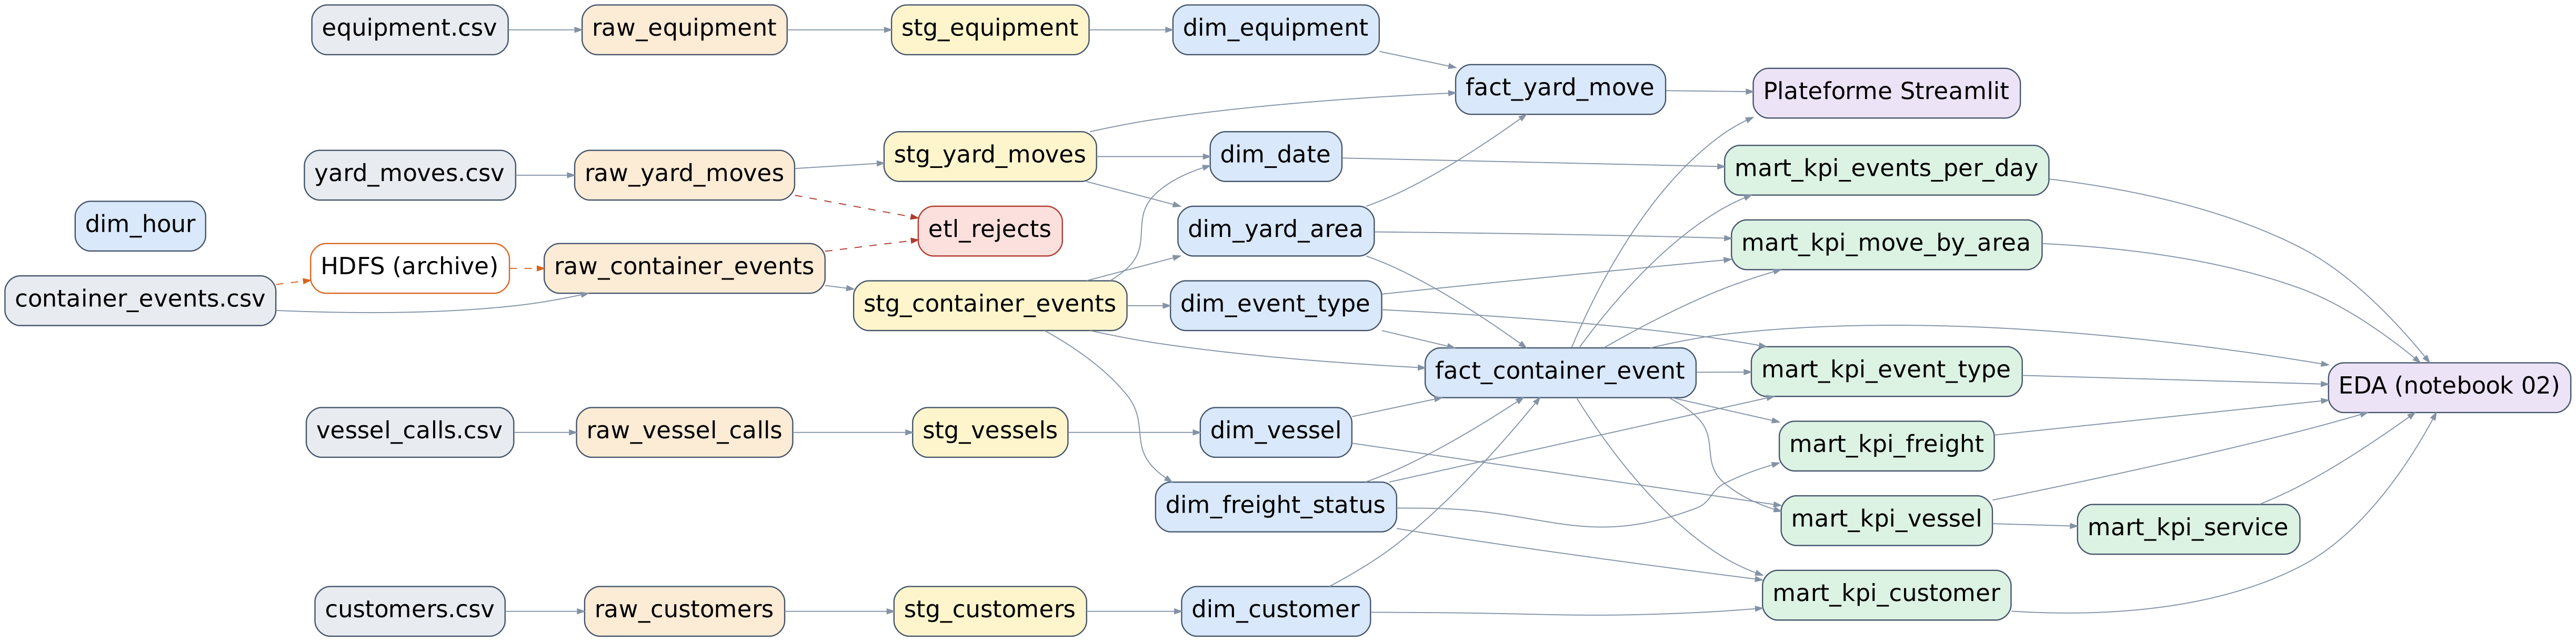

In [11]:
if shutil.which("dot"):
    for fmt, extra in (("png", ["-Gdpi=170"]), ("svg", [])):
        subprocess.run(["dot", f"-T{fmt}", *extra, "-o", f"{OUT_SCHEMA}.{fmt}"], input="\n".join(dot), text=True, check=True)
    print("Schéma écrit : lineage_tables.png / .svg")
else:
    print("Graphviz (commande dot) non installé : on affiche le schéma déjà présent dans le projet.")

from IPython.display import Image
Image(filename=f"{OUT_SCHEMA}.png")